# 04 · The Stories Pair engine: what to suggest, at what price

When the first item of an order is rung, the engine scores every item on the other side of the pair at every
allowed discount and suggests the one with the highest **expected incremental gross profit**, or nothing.

$$
\Delta GP_{i,d} = \underbrace{(1-Q)\,a_i(d)\,gp_i(d)}_{\text{new sales}}
\;-\; \underbrace{Q\,s_i\,\big(p_i - p_i(d)\big)}_{\text{discount given to people who'd buy it anyway}}
\;+\; \underbrace{w\,Q\,(1-s_i)\,\big(gp_i(d) - \overline{gp}_{-i}\big)}_{\text{people who switch to the suggestion}}
$$

| Term | Meaning | Source |
|---|---|---|
| $Q$ | chance the order pairs anyway | **measured** (notebook 03, rate by first-item category) |
| $s_i$ | chance that, if it pairs, the add-on is item $i$ | **measured** (category shares x within-category share) |
| $gp_i(d)$, $p_i$ | gross profit and price of $i$ **at this branch** | **measured** (unit economics) |
| $a_i(d) = r_0 \cdot (K s_i) \cdot (1 + \ell \cdot d/10\%)$ | acceptance by people who would not have added anything | **assumed** ($r_0$, $\ell$) |
| $w$ | share of organic buyers who switch to the suggestion | **assumed** |

Acceptance is proportional to how often people choose the item on their own ($K s_i$ is 1 for an average item), so
a popular item is easier to accept. The assumed values live in `config/assumptions.json`; notebook 05 stress-tests
them and the pilot measures them.

**Guardrails** (`config/guardrails.json`): discount at most 15% (the deepest in Stories' data), at least 40% margin
after discount, the add-on costs at most 2.5x the first item (no $11 sandwich pushed onto a $4 coffee), prices
rounded to $0.05, no suggestion unless expected gain is at least $0.05, never suggest something already in the basket
or already declined.

**What we find**
- At base assumptions the engine **never chooses a discount**: discounting the add-on also pays people who
  would buy it anyway, and discounted drinks in the data were not associated with more pairing. Discounts start to pay only if
  10% off lifts acceptance by about a quarter or more (notebook 05 pins this down across all orders).
- The engine collapses into a **135-row lookup table** (3 branches x 45 first items). Because the chosen models depend
  only on the first item and the branch, this table *is* the engine: a POS can use it on day one with no model server.
- Branch economics change the answer: at Garden, where every unit costs 1.43x more, iced coffees and cold drinks are
  paired with an Egg Sandwich instead of the Chicken Pesto Sandwich suggested at Harbour and Uptown.

In [1]:
# Setup: works in Google Colab, local Jupyter, and from the repo root
import os, sys, subprocess
REPO_URL = "https://github.com/mouhammed-soumaille/EECE-490-Hackathon.git"
if "google.colab" in sys.modules:
    if not os.path.exists("/content/EECE-490-Hackathon"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/EECE-490-Hackathon"], check=True)
    os.chdir("/content/EECE-490-Hackathon")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.join(os.getcwd(), "src"))

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from storiespair import data, models, engine as E, viz
viz.style()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

lines = data.load_lines()
orders = data.build_orders(lines)
added = data.other_side_first_item(lines, orders)
ue = data.unit_economics(lines)
cfg = E.load_config()
pm = models.PairModels.fit(orders, lines, added)          # trained on Jan-May only
engine = E.PairEngine(pm, ue, cfg["compatibility"], E.Assumptions.from_config(cfg), E.Guardrails.from_config(cfg))
engine.a

Assumptions(base_acceptance=0.06, discount_lift_per_10pct=0.1, switch_rate=0.1, offer_rate=0.8)

## 1. The engine at the till

In [2]:
def card(r):
    if not r["offer"]:
        return f"No suggestion. {r['reason']}"
    save = f" (save ${r['saving']:.2f})" if r["saving"] > 0 else ""
    return (f"[{r['pairing_name']}] {r['first_item']} + {r['suggested_item']} for ${r['combo_total']:.2f}{save}\n"
            f"   staff view: expected gain ${r['expected_gain']:.2f} per order shown | {r['reason']}")

scenarios = [
    ("Harbour", "2026-06-03 08:40", ["Cappuccino"]),
    ("Garden", "2026-06-03 21:15", ["Iced Matcha"]),
    ("Uptown", "2026-06-03 13:05", ["Chicken Pesto Sandwich"]),
    ("Harbour", "2026-06-03 16:30", ["Brownie"]),
    ("Garden", "2026-06-03 13:05", ["Lemonade"]),
    ("Harbour", "2026-06-03 13:05", ["Lemonade"]),
    ("Harbour", "2026-06-03 13:05", ["Cappuccino", "Butter Croissant"]),
]
for branch, when, basket in scenarios:
    print(f"{branch} {when[-5:]}  basket={basket}")
    print("  " + card(engine.recommend(branch, when, basket)) + "\n")

Harbour 08:40  basket=['Cappuccino']
  [Morning Pairing] Cappuccino + Egg Sandwich for $12.81
   staff view: expected gain $0.35 per order shown | When a Hot Coffee item is rung first, 14% of the customers who add something pick breakfast. The Egg Sandwich earns $5.45 gross profit per acceptance at Harbour: the highest expected gain once customers who would have added it anyway are accounted for.

Garden 21:15  basket=['Iced Matcha']
  [Evening Pairing] Iced Matcha + Butter Croissant for $10.50
   staff view: expected gain $0.24 per order shown | When a Matcha & Tea item is rung first, 78% of the customers who add something pick bakery. The Butter Croissant earns $2.02 gross profit per acceptance at Garden: the highest expected gain once customers who would have added it anyway are accounted for.

Uptown 13:05  basket=['Chicken Pesto Sandwich']
  [Lunch Pairing] Chicken Pesto Sandwich + Peach Iced Tea for $14.59
   staff view: expected gain $0.26 per order shown | When a Sandwiches ite

### Why the engine picked the Egg Sandwich for a morning cappuccino at Harbour

Top candidates, with each term of the formula. The Butter Croissant is the item most often added, but it earns
$2.69; the Egg Sandwich is added less often but earns $5.45, so its expected gain is higher.

In [3]:
r = engine.recommend("Harbour", "2026-06-03 08:40", ["Cappuccino"])
cand = r["candidates"]
top = (cand[cand.allowed].sort_values("expected_gain", ascending=False)
       .drop_duplicates("item").head(8)[["item", "category", "discount", "offer_price", "gp_if_accepted", "item_share",
                                         "acceptance_new", "expected_gain"]])
top.round(3)

,item,category,discount,offer_price,gp_if_accepted,item_share,acceptance_new,expected_gain
36,Egg Sandwich,Breakfast,0.0,8.56,5.45,0.056,0.074,0.349
32,Avocado Toast,Breakfast,0.0,9.92,5.74,0.051,0.067,0.342
64,Halloumi Wrap,Sandwiches,0.0,10.45,6.31,0.041,0.054,0.315
72,Turkey & Cheese Sandwich,Sandwiches,0.0,10.13,5.41,0.043,0.057,0.273
12,Butter Croissant,Bakery,0.0,3.83,2.69,0.090,0.119,0.228
68,Tuna Sandwich,Sandwiches,0.0,9.29,5.56,0.029,0.038,0.198
40,Granola Yoghurt,Breakfast,0.0,8.24,4.92,0.033,0.044,0.189
24,Cinnamon Roll,Bakery,0.0,5.41,3.17,0.060,0.079,0.183


## 2. Should the add-on be discounted?

In [4]:
r = engine.recommend("Harbour", "2026-06-03 08:40", ["Cappuccino"])
c = r["candidates"]
egg = c[c["item"] == r["suggested_item"]][["discount", "offer_price", "acceptance_new", "gp_if_accepted", "expected_gain"]]
print(f"Suggested item: {r['suggested_item']} at Harbour, base assumptions (10% off lifts acceptance by 10%)")
egg.round(3)

Suggested item: Egg Sandwich at Harbour, base assumptions (10% off lifts acceptance by 10%)


,discount,offer_price,acceptance_new,gp_if_accepted,expected_gain
36,0.00,8.56,0.074,5.45,0.349
37,0.05,8.15,0.078,5.04,0.328
38,0.10,7.70,0.081,4.59,0.300
39,0.15,7.30,0.085,4.19,0.274


In [5]:
lifts = [0.0, 0.1, 0.25, 0.5, 1.0, 1.5]
rows = []
for l in lifts:
    eng_l = E.PairEngine(pm, ue, cfg["compatibility"], replace(engine.a, discount_lift_per_10pct=l), engine.g)
    rr = eng_l.recommend("Harbour", "2026-06-03 08:40", ["Cappuccino"])
    rows.append({"acceptance lift per 10% off": f"+{l:.0%}", "engine picks": rr["suggested_item"],
                 "discount": f"{rr['discount']:.0%}", "expected gain": round(rr["expected_gain"], 3)})
pd.DataFrame(rows)

,acceptance lift per 10% off,engine picks,discount,expected gain
0,+0%,Egg Sandwich,0%,0.349
1,+10%,Egg Sandwich,0%,0.349
2,+25%,Egg Sandwich,5%,0.350
3,+50%,Egg Sandwich,15%,0.423
4,+100%,Egg Sandwich,15%,0.609
5,+150%,Egg Sandwich,15%,0.795


A discount only wins when it changes behaviour a lot, because every discount is also paid to the customers who were
going to buy the item anyway. Stories' own data shows no behaviour change from discounts (notebook 01), so the
default is a **full-price pairing**. Notebook 05 finds the exact lift at which discounting starts to pay.

## 3. The playbook: the whole engine as a lookup table

In [6]:
playbook = engine.playbook()
os.makedirs("outputs", exist_ok=True)
playbook.to_csv("outputs/playbook.csv", index=False)
print(f"{len(playbook)} rows saved to outputs/playbook.csv")
playbook.pivot(index="first_item", columns="branch", values="suggest").head(12)

135 rows saved to outputs/playbook.csv


branch,Garden,Harbour,Uptown
first_item,,,
Almond Croissant,Iced Latte,Iced Latte,Iced Latte
Americano,Butter Croissant,Butter Croissant,Butter Croissant
Avocado Toast,Iced Latte,Iced Latte,Iced Latte
Banana Bread,Iced Latte,Iced Latte,Iced Latte
Blueberry Muffin,Iced Latte,Iced Latte,Iced Latte
Brownie,Iced Matcha,Iced Matcha,Iced Matcha
Butter Croissant,Iced Latte,Iced Latte,Iced Latte
Cappuccino,Egg Sandwich,Egg Sandwich,Egg Sandwich
Caramel Latte,Egg Sandwich,Egg Sandwich,Egg Sandwich


In [7]:
w = playbook.pivot(index="first_item", columns="branch", values="suggest")
diff = w[w.nunique(axis=1) > 1]
print(f"{len(diff)} of {len(w)} first items get a different suggestion depending on the branch:")
diff

7 of 45 first items get a different suggestion depending on the branch:


branch,Garden,Harbour,Uptown
first_item,,,
Coffee Frappe,Egg Sandwich,Chicken Pesto Sandwich,Chicken Pesto Sandwich
Cold Brew,Egg Sandwich,Chicken Pesto Sandwich,Chicken Pesto Sandwich
Fresh Orange Juice,Egg Sandwich,Chicken Pesto Sandwich,Chicken Pesto Sandwich
Iced Latte,Egg Sandwich,Chicken Pesto Sandwich,Chicken Pesto Sandwich
Iced Mocha,Egg Sandwich,Chicken Pesto Sandwich,Chicken Pesto Sandwich
Lemonade,Egg Sandwich,Chicken Pesto Sandwich,Chicken Pesto Sandwich
Peach Iced Tea,Egg Sandwich,Chicken Pesto Sandwich,Chicken Pesto Sandwich


In [8]:
gp_cmp = ue[ue["product"].isin(["Chicken Pesto Sandwich", "Egg Sandwich"])].pivot(index="product", columns="branch", values="unit_gp")
print("Unit gross profit (USD):")
gp_cmp.round(2)

Unit gross profit (USD):


branch,Garden,Harbour,Uptown
product,,,
Chicken Pesto Sandwich,3.36,6.12,5.36
Egg Sandwich,3.70,5.45,4.83


At Garden the Chicken Pesto Sandwich earns $3.36 a unit against $6.12 at Harbour, so the engine switches to the Egg
Sandwich there. A franchise-wide combo would miss this.

In [9]:
summary = (playbook.groupby(["branch", "suggest"]).size().unstack(fill_value=0).T)
summary["total"] = summary.sum(axis=1)
summary.sort_values("total", ascending=False)

branch,Garden,Harbour,Uptown,total
suggest,,,,
Iced Latte,11,11,11,33
Butter Croissant,10,10,10,30
Egg Sandwich,13,6,6,25
Peach Iced Tea,7,7,7,21
Chicken Pesto Sandwich,0,7,7,14
Iced Matcha,4,4,4,12


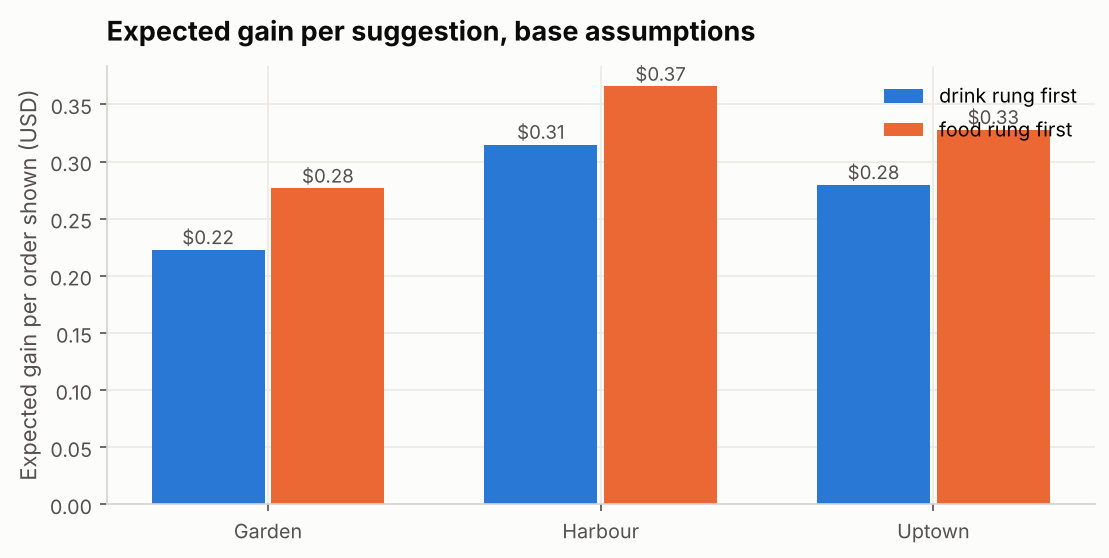

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
pb = playbook.copy()
pb["side"] = np.where(pb.first_category.isin(data.DRINK_CATEGORIES), "drink first", "food first")
agg = pb.groupby(["branch", "side"]).expected_gain_per_order.mean().unstack()
x = np.arange(len(agg))
ax.bar(x - 0.18, agg["drink first"], width=0.34, color=viz.BLUE, label="drink rung first")
ax.bar(x + 0.18, agg["food first"], width=0.34, color=viz.ORANGE, label="food rung first")
for i, (a_, b_) in enumerate(agg.values):
    ax.text(i - 0.18, a_ + 0.005, f"${a_:.2f}", ha="center", fontsize=9, color=viz.INK_2)
    ax.text(i + 0.18, b_ + 0.005, f"${b_:.2f}", ha="center", fontsize=9, color=viz.INK_2)
ax.set_xticks(x, agg.index)
ax.set_ylabel("Expected gain per order shown (USD)")
ax.set_title("Expected gain per suggestion, base assumptions")
ax.legend(loc="upper right")
viz.savefig(fig, "04_expected_gain_by_branch")
plt.show()

Garden earns the least per suggestion for the same behaviour, a direct consequence of its unit costs. Fixing
Garden's costs (notebook 01 side finding) would raise the value of every suggestion made there.